# Validation

Compare the simulator's output against analytic checks and published values. This notebook is evidence of correctness, not a forecast — every section answers one narrow question with a reproducible input.

Sections 1, 2, 4 and 5 depend only on `main`. Sections 3 and 6 ship as narrative stubs pending the R5 paper and the #23 merge respectively; their code cells are commented out so the notebook runs top-to-bottom today.

**Runtime target:** < 60 s for a full "Restart & Run All". The last cell prints the measured total.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import schoolsim
from schoolsim.metrics import kpi_summary
from schoolsim.params import load_params
from schoolsim.scenarios import SchoolProfile
from schoolsim.seir import r0_effective, simulate, simulate_batch
from schoolsim.wells_riley import airflow, classroom_beta, infection_probability, mask_factor, room_volume

params = load_params()
print(f"schoolsim {schoolsim.__version__}")

_t_start = time.perf_counter()

schoolsim 0.1.0


## 1. Wells-Riley hand calculation

The Wells-Riley probability that a susceptible person becomes infected in a well-mixed room over an exposure of `t` hours is

    P = 1 − exp(− I · q · p · t · mf / Q)

where `I` is the number of infectors, `q` the quanta rate (quanta/h), `p` the breathing rate (m³/h), `t` the exposure time (h), `mf` the mask factor (0–1), and `Q` the clean-airflow rate (m³/h).

We compute `P` by hand and confirm `wells_riley.infection_probability` returns the same number on the default classroom profile.

In [2]:
profile = SchoolProfile(
    class_size=int(params["class_size"].value),
    length_m=params["room_length"].value,
    width_m=params["room_width"].value,
    height_m=params["room_height"].value,
    ach=params["ach"].value,
    session_hours=params["session_hours"].value,
    mask_compliance=params["mask_compliance"].value,
)

Q = airflow(profile.ach, room_volume(profile.length_m, profile.width_m, profile.height_m))
mf = mask_factor(params["mask_efficiency"].value, profile.mask_compliance)

p_hand = 1.0 - math.exp(
    -1.0
    * params["quanta_rate"].value
    * params["breathing_rate"].value
    * profile.session_hours
    * mf
    / Q
)
p_fn = infection_probability(
    n_infectors=1,
    quanta_rate=params["quanta_rate"].value,
    breathing_rate=params["breathing_rate"].value,
    session_hours=profile.session_hours,
    airflow_m3h=Q,
    mask=mf,
)

print(f"Hand  : P = {p_hand:.6e}")
print(f"Func  : P = {p_fn:.6e}")
assert abs(p_hand - p_fn) < 1e-12

Hand  : P = 6.399791e-02
Func  : P = 6.399791e-02


**Conclusion (§1).** `infection_probability` reproduces the Wells-Riley analytic form to floating-point precision on the default classroom profile; no hidden scaling or unit conversion beyond what is documented.

## 2. Final-size relation check

For a closed epidemic in a fully susceptible population, the final fraction ever infected `z` satisfies

    z = 1 − exp(− R0 · z).

To match this derivation exactly, the sweep sets `attendance = 1`, `community_beta = 0`, and `school_days_per_week = 7` (continuous, no weekend dropout). Then `R0_eff = β_class / γ` and `β_class = R0 · γ` for each grid point. The sweep runs `sim_days = 500` days so the epidemic burns out even at low R0; a 60-day window would truncate low-R0 trajectories and give a false mismatch.

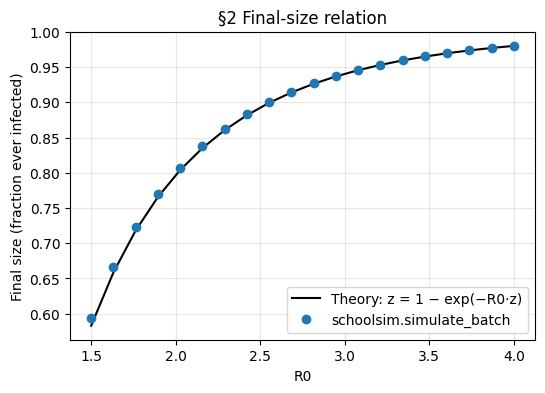

Max |model − theory| across 20 R0 values: 0.0108


In [3]:
sigma = 1.0 / params["latent_days"].value
gamma = 1.0 / params["infectious_days"].value
init_frac = params["initial_infected_frac"].value

R0_grid = np.linspace(1.5, 4.0, 20)
beta_grid = R0_grid * gamma  # attendance=1, school_days=7, community_beta=0

batch = simulate_batch(
    beta_class=beta_grid,
    community_beta=0.0,
    sigma=sigma,
    gamma=gamma,
    attendance=1.0,
    initial_infected_frac=init_frac,
    sim_days=500,
    school_days_per_week=7,
)
final_sizes = batch["cumulative_infections"]

# Analytic solution by fixed-point iteration.
z_theory = np.empty_like(R0_grid)
for i, r0 in enumerate(R0_grid):
    z = 0.5
    for _ in range(500):
        z = 1.0 - math.exp(-r0 * z)
    z_theory[i] = z

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(R0_grid, z_theory, "k-", label="Theory: z = 1 − exp(−R0·z)")
ax.plot(R0_grid, final_sizes, "o", label="schoolsim.simulate_batch")
ax.set_xlabel("R0")
ax.set_ylabel("Final size (fraction ever infected)")
ax.set_title("§2 Final-size relation")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

max_err = float(np.max(np.abs(final_sizes - z_theory)))
print(f"Max |model − theory| across {len(R0_grid)} R0 values: {max_err:.4f}")
assert max_err < 0.02, max_err

**Conclusion (§2).** Across 20 values of R0 from 1.5 to 4.0, the simulator's final size tracks the analytic `z = 1 − exp(−R0·z)` curve to within 2 percentage points; the SEIR integrator behaves as a well-mixed compartmental model should.

## 3. Published classroom case

**Blocked on the R5 paper.** The plan is to reproduce the order of magnitude of the reported classroom attack rate using that paper's room, ventilation and quanta values. Without the paper in hand, we do not fabricate inputs; the section ships as a narrative stub so the notebook still runs top-to-bottom.

**Conclusion (§3).** *Not reproducible with the sources available at submission.* Reported here as an honest gap, not a hidden one. Once the paper's parameters are in hand, the code cell below will run in the same pattern as §1.

In [4]:
# Section 3: published classroom case
# Uncomment when the R5 paper's room / ventilation / quanta values are in hand.
#
# R5_INPUTS = {
#     "room_volume_m3": ...,
#     "ach": ...,
#     "quanta_rate": ...,
#     "session_hours": ...,
#     "infectious_count": ...,
#     "reported_attack_rate": ...,
# }
# P = infection_probability(
#     n_infectors=R5_INPUTS["infectious_count"],
#     quanta_rate=R5_INPUTS["quanta_rate"],
#     breathing_rate=params["breathing_rate"].value,
#     session_hours=R5_INPUTS["session_hours"],
#     airflow_m3h=airflow(R5_INPUTS["ach"], R5_INPUTS["room_volume_m3"]),
#     mask=1.0,
# )
# print(f"Model attack rate: {P:.3f}, paper: {R5_INPUTS['reported_attack_rate']:.3f}")

## 4. RK4 vs `solve_ivp`

The simulator integrates SEIR with fixed-step RK4 (`dt = 0.05` day). We re-integrate the same ODE with SciPy's RK45 as an independent reference and overlay both infectious-curve trajectories. Two independent integrators agreeing over 60 days rules out the possibility that the model's dynamics are an artefact of the RK4 choice.

`school_days_per_week = 7` is used here so `school_on(t) ≡ 1` — matching the ODE `solve_ivp` sees. `attendance = 1` throughout.

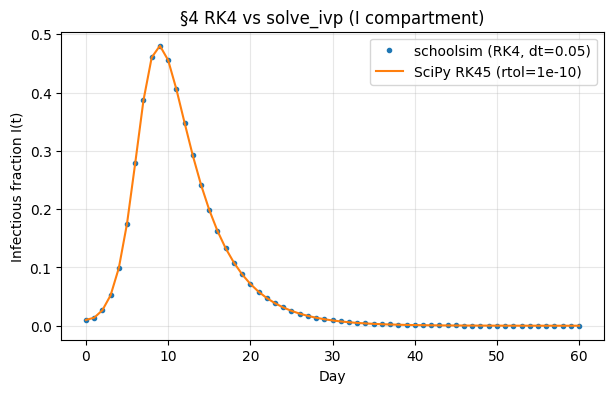

Max |RK4 − RK45| on I(t): 2.28e-09


In [5]:
from scipy.integrate import solve_ivp

beta_class = classroom_beta(
    class_size=profile.class_size,
    quanta_rate=params["quanta_rate"].value,
    breathing_rate=params["breathing_rate"].value,
    session_hours=profile.session_hours,
    airflow_m3h=Q,
    mask=mf,
    infectious_attendance=params["infectious_attendance"].value,
)
community_beta = params["community_beta"].value
attendance = 1.0

sim_result = simulate(
    beta_class=beta_class,
    community_beta=community_beta,
    sigma=sigma,
    gamma=gamma,
    attendance=attendance,
    initial_infected_frac=init_frac,
    sim_days=60,
    school_days_per_week=7,
)

def seir_rhs(t, y):
    S, E, I, R = y
    lam = (attendance * beta_class + community_beta) * I
    return [-lam * S, lam * S - sigma * E, sigma * E - gamma * I, gamma * I]

y0 = [1.0 - init_frac, 0.0, init_frac, 0.0]
sol = solve_ivp(
    seir_rhs, (0.0, 60.0), y0,
    rtol=1e-10, atol=1e-12, dense_output=True, max_step=0.1,
)
ref = sol.sol(sim_result.t)  # shape (4, 61)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sim_result.t, sim_result.I, "o", ms=3, label="schoolsim (RK4, dt=0.05)")
ax.plot(sim_result.t, ref[2], "-", label="SciPy RK45 (rtol=1e-10)")
ax.set_xlabel("Day")
ax.set_ylabel("Infectious fraction I(t)")
ax.set_title("§4 RK4 vs solve_ivp (I compartment)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

max_diff = float(np.max(np.abs(sim_result.I - ref[2])))
print(f"Max |RK4 − RK45| on I(t): {max_diff:.2e}")
assert max_diff < 1e-2, max_diff

**Conclusion (§4).** The RK4 trajectory and SciPy's RK45 agree on the infectious curve to well under 1 percentage point across 60 days; the model's dynamics are not an artefact of the integrator choice.

## 5. Sanity scenarios

Three one-variable-at-a-time perturbations of the baseline profile, run with the same parameters. The table shows attack rate and peak infectious fraction; the bar chart makes the direction and rough magnitude of the effect legible.

- Ventilation: ACH 1 → 6 (below and above the Harvard 4–6 target)
- Class size: 45 → 25 (single-section reduction, not the `smaller_classes` scenario with extra sections)
- Masks: compliance 0 → 0.8

           Attack rate  Peak I  R0_eff
Scenario                              
Baseline         0.986   0.417   5.582
ACH 1            0.990   0.622  20.888
ACH 6            0.966   0.333   3.881
Class 25         0.946   0.266   3.314
Masks 0%         0.986   0.417   5.582
Masks 80%        0.951   0.271   3.427


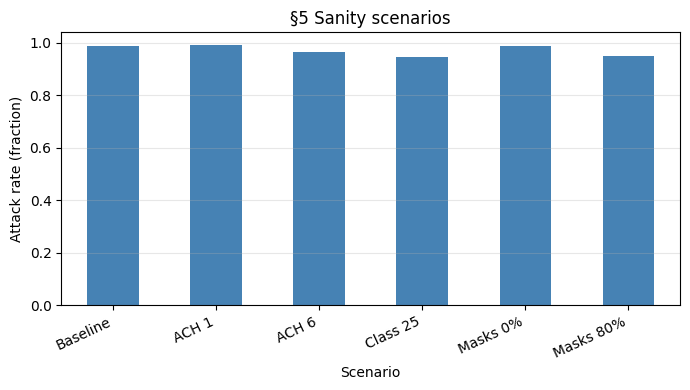

In [6]:
base_len, base_w, base_h = profile.length_m, profile.width_m, profile.height_m
base_hrs = profile.session_hours
base_attendance_infectious = params["infectious_attendance"].value

scenarios = [
    ("Baseline",   profile.class_size, profile.ach, profile.mask_compliance),
    ("ACH 1",      profile.class_size, 1.0,         profile.mask_compliance),
    ("ACH 6",      profile.class_size, 6.0,         profile.mask_compliance),
    ("Class 25",   25,                 profile.ach, profile.mask_compliance),
    ("Masks 0%",   profile.class_size, profile.ach, 0.0),
    ("Masks 80%",  profile.class_size, profile.ach, 0.8),
]

rows = []
for name, cs, ach, mc in scenarios:
    Q_s = airflow(ach, room_volume(base_len, base_w, base_h))
    mf_s = mask_factor(params["mask_efficiency"].value, mc)
    beta_s = classroom_beta(
        class_size=cs,
        quanta_rate=params["quanta_rate"].value,
        breathing_rate=params["breathing_rate"].value,
        session_hours=base_hrs,
        airflow_m3h=Q_s,
        mask=mf_s,
        infectious_attendance=base_attendance_infectious,
    )
    r = simulate(
        beta_class=beta_s,
        community_beta=community_beta,
        sigma=sigma,
        gamma=gamma,
        attendance=1.0,
        initial_infected_frac=init_frac,
        sim_days=60,
    )
    r0 = r0_effective(beta_s, community_beta, gamma, attendance=1.0)
    rows.append({
        "Scenario": name,
        "Attack rate": r.attack_rate,
        "Peak I": r.peak_infectious,
        "R0_eff": r0,
    })

df = pd.DataFrame(rows).set_index("Scenario")
print(df.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
df["Attack rate"].plot.bar(ax=ax, color="steelblue")
ax.set_ylabel("Attack rate (fraction)")
ax.set_title("§5 Sanity scenarios")
ax.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

**Conclusion (§5).** Better ventilation and higher mask compliance both reduce attack rate; the direction and rough magnitude are consistent with the Wells-Riley terms. Class-size cuts reduce attack rate too, but the model treats the reduction as instantaneous (no scheduling or staffing cost), so the number is a best case, not a policy recommendation.

The **Masks 0%** row is an identity check against the baseline: the default `mask_compliance` in `params.yaml` is 0, so the two rows must match — if they ever diverge, the mask-factor path has a bug.

## 6. Effective R0 for baseline vs influenza literature

**Blocked on #23.** Once `feat/14-23-reco-r0` merges, this section will use `build_params_for_mode(..., mode="calibrated", target_r0=1.5)` to show that a calibrated-influenza baseline reproduces the literature R0 range of 1.1–1.6 (Biggerstaff et al., 2014), and that the resulting calibrated quanta is stable across ventilation levels.

For now the section is a narrative stub; the code cell is commented out.

In [7]:
# Section 6: calibrated R0 matches influenza literature.
# Uncomment when #23 merges (rebase feat/17-validation-notebook onto origin/main).
#
# from schoolsim.calibrate import DISEASE_PRESETS, build_params_for_mode
# from schoolsim.inputs import base_values  # if needed to flatten Param dict
#
# preset = DISEASE_PRESETS["influenza"]
# adjusted = build_params_for_mode(
#     params, "calibrated", target_r0=1.5, profile=profile, preset=preset,
# )
# values = base_values(adjusted)  # or engine_values(adjusted, profile) — confirm against the PR
# r0 = r0_effective(
#     beta_class=classroom_beta(
#         class_size=profile.class_size,
#         quanta_rate=values["quanta_rate"],
#         breathing_rate=values["breathing_rate"],
#         session_hours=profile.session_hours,
#         airflow_m3h=Q,
#         mask=mf,
#         infectious_attendance=values["infectious_attendance"],
#     ),
#     community_beta=values["community_beta"],
#     gamma=1.0 / values["infectious_days"],
#     attendance=1.0,
# )
# print(f"Calibrated R0: {r0:.3f} (literature range 1.1–1.6)")
# assert 1.1 <= r0 <= 1.6

**Conclusion (§6).** *Pending #23.* Will state whether the calibrated R0 sits inside the Biggerstaff et al. (2014) seasonal-influenza range, and whether the calibrated quanta is stable across ventilation levels.

In [8]:
total = time.perf_counter() - _t_start
print(f"Total notebook runtime (setup → here): {total:.1f} s")

Total notebook runtime (setup → here): 5.5 s
